In [9]:
from torchvision import transforms
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import os
from glob import glob
from PIL import Image
import random
import torchvision.transforms.functional as F
import json
import torch
from tqdm import tqdm

In [10]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

Using device: cuda


In [11]:
crop_size = 32
batch_size = 64

In [12]:
class ImageDataset(Dataset):

    def __init__(self, split, transform=None):
        self.transform = transform

        # get the dictionnary with the crop's infos
        with open(f'data/dataset_crops/{split}_{crop_size}x{crop_size}_data.json', 'r', encoding='utf-8') as f:
            dico = json.load(f)

        # get all image paths, attributs and classes
        self.data = []

        for path in glob(os.path.join(f"data/dataset_crops/{split}", "**", "*.png"), recursive=True):
            filename = os.path.basename(path)      # "crop_i.png"
            crop_name = os.path.splitext(filename)[0]   # "crop_i"

            attributs = dico[crop_name]["attributs"]
            damage = dico[crop_name]["niveau de brûlé"]

            self.data.append((path, attributs, damage))


    def __len__(self):
        return len(self.data)


    def __getitem__(self, idx):
        img_path, attribut, label = self.data[idx]

        img = Image.open(img_path).convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        attribut = torch.tensor(attribut, dtype=torch.float32)
        label = torch.tensor(label, dtype=torch.int64)

        return img, attribut, label


# transformations ajoutées pour faire de la data augmentation autrement il y a de l'overfitting

def random_90_rotation(img):
    angles = [0, 90, 180, 270]
    return F.rotate(img, angle=random.choice(angles))

transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

In [21]:
train_dataset = ImageDataset(split="val", transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=6)

In [22]:
print(len(train_dataset))

imgs, attributs, classes = next(iter(train_loader))

print(imgs.shape, attributs.shape, classes.shape)

99236
torch.Size([64, 3, 32, 32]) torch.Size([64, 60]) torch.Size([64])


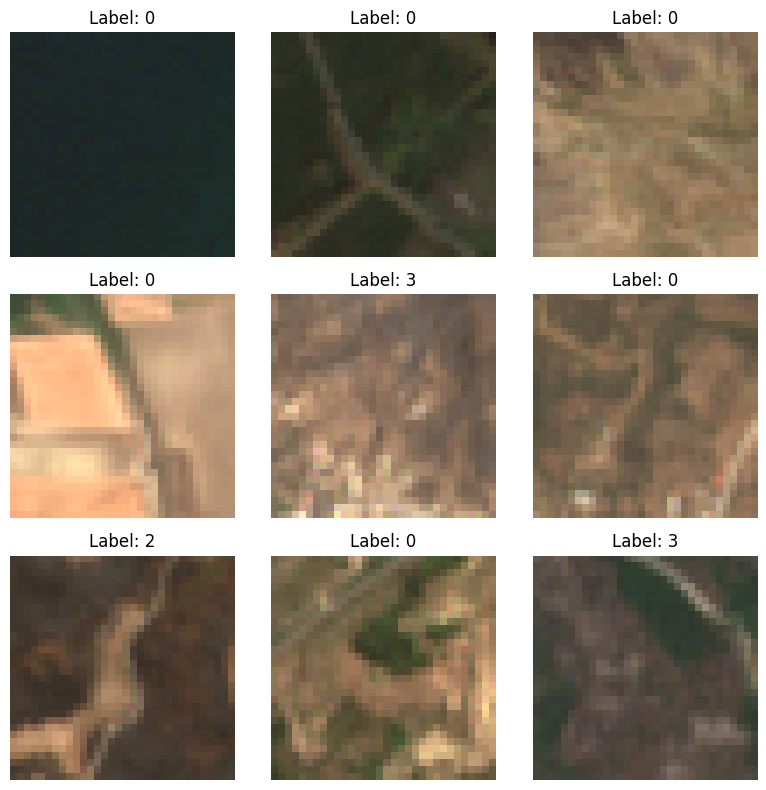

In [23]:
# Afficher une grille 3x3 d'exemples
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i in range(3):
    for j in range(3):
        imgs, attributs, classes = next(iter(train_loader))
        axes[i, j].imshow((imgs[0].permute(1, 2, 0).numpy() + 1)/2)
        axes[i, j].set_title(f"Label: {classes[0]}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [24]:
for imgs, attributs, classes in tqdm(train_loader):
    imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)


100%|██████████| 1551/1551 [00:11<00:00, 134.18it/s]
